# Тема 5. Законы распределения дискретных случайных величин



In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.precision", 6)
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11


## 1. Биномиальный закон распределения

### Условие задачи

На производственной линии проверяют качество электронных микросхем. Вероятность того, что случайно выбранная микросхема пройдёт проверку без дефектов, равна $0{,}8$. Проверяют $6$ микросхем, результаты независимы.

Случайная величина $X$ — количество микросхем, прошедших проверку без дефектов.

Поскольку проводится $n=6$ независимых испытаний с одинаковой вероятностью успеха $p=0{,}8$, случайная величина имеет биномиальное распределение:

$$
X \sim B(n, p), \qquad P(X=k) = C_n^k \, p^k (1-p)^{\,n-k}.
$$

Числовые характеристики биномиального распределения:

$$
M(X) = np, \qquad D(X) = np(1-p), \qquad \sigma(X) = \sqrt{np(1-p)}.
$$


In [3]:
n = 6
p = 0.8
x_bin = np.arange(0, n + 1)
prob_bin = np.array([
    math.comb(n, int(k)) * p**k * (1-p)**(n-k)
    for k in x_bin
])

table_bin = pd.DataFrame({"k": x_bin, "P(X = k)": prob_bin})
display(table_bin.style.hide(axis='index'))
print(f"Сумма вероятностей: {prob_bin.sum():.6f}")

mean_bin = n * p
var_bin = n * p * (1-p)
std_bin = math.sqrt(var_bin)
mode_bin = int(math.floor((n + 1) * p))

print(f"M(X) = {mean_bin:.6f}")
print(f"D(X) = {var_bin:.6f}")
print(f"σ(X) = {std_bin:.6f}")
print(f"Mo(X) = {mode_bin}")


k,P(X = k)
0,0.000064
1,0.001536
2,0.015360
3,0.081920
4,0.245760
5,0.393216
6,0.262144


Сумма вероятностей: 1.000000
M(X) = 4.800000
D(X) = 0.960000
σ(X) = 0.979796
Mo(X) = 5


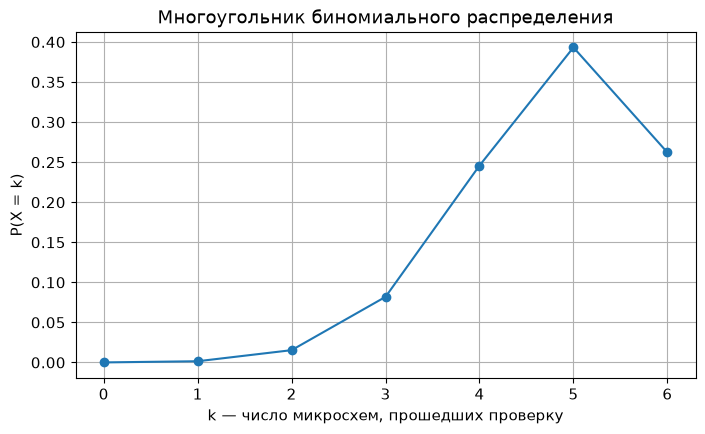

In [4]:
plt.plot(x_bin, prob_bin, marker="o")
plt.title("Многоугольник биномиального распределения")
plt.xlabel("k — число микросхем, прошедших проверку")
plt.ylabel("P(X = k)")
plt.xticks(x_bin)
plt.show()



**Вывод по задаче 1.** В среднем проверку проходят $4{,}8$ микросхемы из шести. Наиболее вероятно, что проверку пройдут $5$ микросхем.

$$
\boxed{\; M(X)=4{,}8; \quad D(X)=0{,}96; \quad \sigma(X)\approx 0{,}979796; \quad Mo(X)=5. \;}
$$

## 2. Закон распределения Пуассона

### Условие задачи

На сервер технической поддержки в среднем поступает $2{,}5$ автоматических сообщения об ошибках за минуту. Предполагается, что сообщения поступают независимо, а средняя интенсивность поступления постоянна.

Случайная величина $X$ — количество сообщений об ошибках, поступивших за одну минуту.

Используем распределение Пуассона с параметром $\lambda = 2{,}5$:

$$
P(X=k) = \frac{\lambda^k}{k!}\, e^{-\lambda}, \qquad k = 0, 1, 2, \ldots
$$

Для распределения Пуассона:

$$
M(X) = \lambda, \qquad D(X) = \lambda, \qquad \sigma(X) = \sqrt{\lambda}.
$$

In [5]:
lam = 2.5
x_pois = np.arange(0, 9)
prob_pois = np.array([
    math.exp(-lam) * lam**int(k) / math.factorial(int(k))
    for k in x_pois
])

table_pois = pd.DataFrame({"k": x_pois, "P(X = k)": prob_pois})
display(table_bin.style.hide(axis='index'))
print(f"Сумма вероятностей для k = 0,...,8: {prob_pois.sum():.6f}")
print("Примечание: распределение Пуассона продолжается до бесконечности; таблица показывает первые девять значений.")

mean_pois = lam
var_pois = lam
std_pois = math.sqrt(lam)
mode_pois = math.floor(lam)

print(f"M(X) = {mean_pois:.6f}")
print(f"D(X) = {var_pois:.6f}")
print(f"σ(X) = {std_pois:.6f}")
print(f"Mo(X) = {mode_pois}")


k,P(X = k)
0,0.000064
1,0.001536
2,0.015360
3,0.081920
4,0.245760
5,0.393216
6,0.262144


Сумма вероятностей для k = 0,...,8: 0.998860
Примечание: распределение Пуассона продолжается до бесконечности; таблица показывает первые девять значений.
M(X) = 2.500000
D(X) = 2.500000
σ(X) = 1.581139
Mo(X) = 2


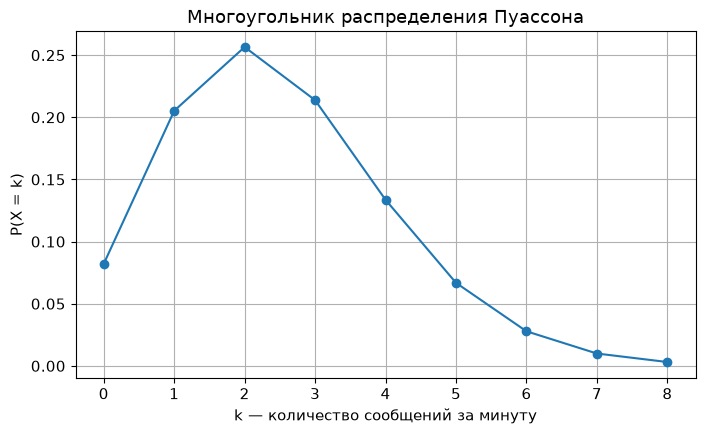

In [6]:
plt.plot(x_pois, prob_pois, marker="o")
plt.title("Многоугольник распределения Пуассона")
plt.xlabel("k — количество сообщений за минуту")
plt.ylabel("P(X = k)")
plt.xticks(x_pois)
plt.show()


**Вывод по задаче 2.** В среднем за минуту поступает $2{,}5$ сообщения. Наиболее вероятное количество сообщений за минуту — $2$.

$$
\boxed{\; M(X)=2{,}5; \quad D(X)=2{,}5; \quad \sigma(X)\approx 1{,}581139; \quad Mo(X)=2. \;}
$$

## 3. Геометрический закон распределения

### Условие задачи

Инженер проверяет новый датчик, который при каждом включении независимо проходит тест с вероятностью $p=0{,}3$. Испытания повторяются до первого успешного прохождения теста.

Случайная величина $X$ — номер испытания, на котором датчик впервые успешно проходит тест.

Для геометрического распределения, где отсчёт начинается с первого испытания:

$$
P(X=k) = (1-p)^{\,k-1}\, p, \qquad k = 1, 2, 3, \ldots
$$

Числовые характеристики:

$$
M(X) = \frac{1}{p}, \qquad D(X) = \frac{1-p}{p^2}, \qquad \sigma(X) = \sqrt{\frac{1-p}{p^2}}.
$$

In [8]:
p_geo = 0.3
x_geo = np.arange(1, 11)
prob_geo = np.array([(1-p_geo)**(int(k)-1) * p_geo for k in x_geo])

table_geo = pd.DataFrame({"k": x_geo, "P(X = k)": prob_geo})
display(table_geo.style.hide(axis='index'))
print(f"Сумма вероятностей для k = 1,...,10: {prob_geo.sum():.6f}")
print("Примечание: геометрическое распределение бесконечно; в таблице приведены первые десять значений.")

mean_geo = 1 / p_geo
var_geo = (1-p_geo) / p_geo**2
std_geo = math.sqrt(var_geo)
mode_geo = 1 

print(f"M(X) = {mean_geo:.6f}")
print(f"D(X) = {var_geo:.6f}")
print(f"σ(X) = {std_geo:.6f}")
print(f"Mo(X) = {mode_geo}")


k,P(X = k)
1,0.300000
2,0.210000
3,0.147000
4,0.102900
5,0.072030
6,0.050421
7,0.035295
8,0.024706
9,0.017294
10,0.012106


Сумма вероятностей для k = 1,...,10: 0.971752
Примечание: геометрическое распределение бесконечно; в таблице приведены первые десять значений.
M(X) = 3.333333
D(X) = 7.777778
σ(X) = 2.788867
Mo(X) = 1


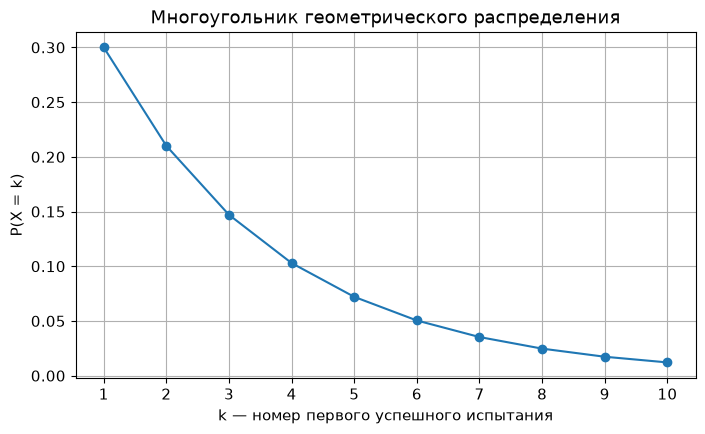

In [9]:
plt.plot(x_geo, prob_geo, marker="o")
plt.title("Многоугольник геометрического распределения")
plt.xlabel("k — номер первого успешного испытания")
plt.ylabel("P(X = k)")
plt.xticks(x_geo)
plt.show()


**Вывод по задаче 3.** В среднем первый успешный результат достигается на третьем с небольшим испытании (математическое ожидание равно $3{,}33$). Наиболее вероятно, что датчик пройдёт тест уже при первом включении.

$$
\boxed{\; M(X)\approx 3{,}333333; \quad D(X)\approx 7{,}777778; \quad \sigma(X)\approx 2{,}788867; \quad Mo(X)=1. \;}
$$

## 4. Гипергеометрический закон распределения

### Условие задачи

На складе находится партия из $20$ электронных компонентов, среди которых $7$ имеют дефект, а $13$ исправны. Для контроля качества случайным образом без возвращения выбирают $5$ компонентов.

Случайная величина $X$ — количество дефектных компонентов в выбранной пятёрке.

Поскольку выбор проводится **без возвращения** из конечной партии, вероятность зависит от предыдущих результатов. Поэтому используется гипергеометрическое распределение:

$$
P(X=k) = \frac{C_K^k \, C_{N-K}^{\,n-k}}{C_N^n},
$$

где $N=20$ — общий объём партии, $K=7$ — количество дефектных компонентов, $n=5$ — объём выборки.

Возможные значения: $k = 0, 1, 2, 3, 4, 5$.

Числовые характеристики:

$$
M(X) = n\frac{K}{N},
$$

$$
D(X) = n\frac{K}{N}\left(1-\frac{K}{N}\right)\frac{N-n}{N-1}, \qquad \sigma(X) = \sqrt{D(X)}.
$$

In [ ]:
N = 20
K = 7
n_sample = 5
x_hyp = np.arange(max(0, n_sample-(N-K)), min(n_sample, K) + 1)
denom = math.comb(N, n_sample)
prob_hyp = np.array([
    math.comb(K, int(k)) * math.comb(N-K, n_sample-int(k)) / denom
    for k in x_hyp
])

table_hyp = pd.DataFrame({"k": x_hyp, "P(X = k)": prob_hyp})
display(table_hyp.style.hide(axis='index'))
print(f"Сумма вероятностей: {prob_hyp.sum():.6f}")

mean_hyp = n_sample * K / N
var_hyp = n_sample * (K/N) * (1-K/N) * ((N-n_sample)/(N-1))
std_hyp = math.sqrt(var_hyp)

mode_hyp = int(x_hyp[np.argmax(prob_hyp)])

print(f"M(X) = {mean_hyp:.6f}")
print(f"D(X) = {var_hyp:.6f}")
print(f"σ(X) = {std_hyp:.6f}")
print(f"Mo(X) = {mode_hyp}")


k,P(X = k)
0,0.083011
1,0.322820
2,0.387384
3,0.176084
4,0.029347
5,0.001354


Сумма вероятностей: 1.000000
M(X) = 1.750000
D(X) = 0.898026
σ(X) = 0.947643
Mo(X) = 2


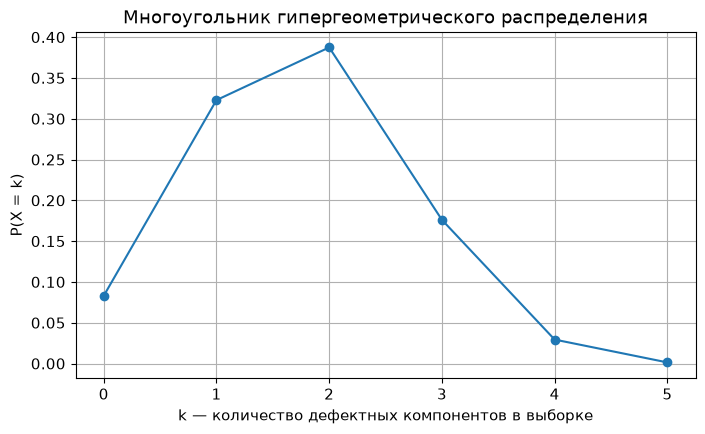

In [11]:
plt.plot(x_hyp, prob_hyp, marker="o")
plt.title("Многоугольник гипергеометрического распределения")
plt.xlabel("k — количество дефектных компонентов в выборке")
plt.ylabel("P(X = k)")
plt.xticks(x_hyp)
plt.show()


**Вывод по задаче 4.** В среднем в выборке из пяти компонентов ожидается $1{,}75$ дефектного компонента. Наиболее вероятно обнаружить $2$ дефектных компонента.

$$
\boxed{\; M(X)=1{,}75; \quad D(X)\approx 0{,}898026; \quad \sigma(X)\approx 0{,}947643; \quad Mo(X)=2. \;}
$$